<a href="https://colab.research.google.com/github/fdegolla/MAT-422-Francisco-Degollado/blob/main/MAT422_HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# MAT 422 - Homework 3.4

**Name:** Francisco Degollado

## Topics

- 3.4 Logistic Regression

## 3.4 Logistic Regression

Logistic regression is a statistical method used to predict the probability of an outcome that belongs to one of two categories. Unlike linear regression, which predicts continuous values, logistic regression is commonly used for binary classification problems.

The logistic regression model uses the sigmoid function:

$$
P(Y=1 \mid X=x)=\frac{1}{1+e^{-(\beta_0+\beta_1 x)}}
$$

where:

- β₀ is the intercept.
- β₁ is the regression coefficient.
- x is the input variable.
- P(Y = 1 | X = x) is the predicted probability of belonging to class 1.

The sigmoid function produces values between 0 and 1, allowing the model to represent probabilities.

Consider a dataset where the number of hours a student studies is used to predict whether the student passes an exam.

We will use Python to fit a logistic regression model, calculate predicted probabilities, and visualize the relationship between study hours and exam outcomes.

In [2]:

# Define the study hours
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)

# Define exam outcomes (0 = Fail, 1 = Pass)
y = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

# Create the logistic regression model
model = LogisticRegression()

# Fit the model to the data
model.fit(X, y)

# Calculate predicted probabilities
probabilities = model.predict_proba(X)[:, 1]

# Predict exam outcomes
predictions = model.predict(X)

# Display the model coefficients
print("Intercept =", round(model.intercept_[0], 4))
print("Coefficient =", round(model.coef_[0][0], 4))

print("\nStudy Hours | Actual | Predicted Probability | Prediction")

for i in range(len(X)):
    print(X[i][0], "          ",
          y[i], "          ",
          round(probabilities[i], 4), "          ",
          predictions[i])

# Calculate classification accuracy
accuracy = accuracy_score(y, predictions)

print("\nModel accuracy =", round(accuracy, 4))


Intercept = -4.9828
Coefficient = 0.9059

Study Hours | Actual | Predicted Probability | Prediction
1            0            0.0167            0
2            0            0.0403            0
3            0            0.0941            0
4            0            0.2044            0
5            1            0.3886            0
6            0            0.6113            1
7            1            0.7955            1
8            1            0.9059            1
9            1            0.9597            1
10            1            0.9833            1

Model accuracy = 0.8


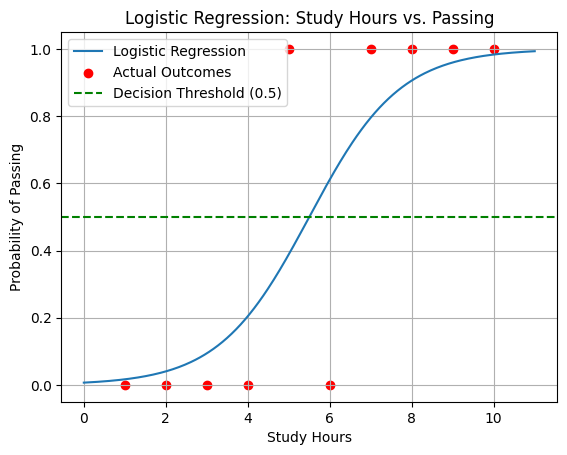

In [3]:

# Create study hour values for a smooth curve
X_curve = np.linspace(0, 11, 300).reshape(-1, 1)

# Calculate predicted probabilities
y_curve = model.predict_proba(X_curve)[:, 1]

# Plot the logistic regression curve
plt.plot(X_curve, y_curve, label="Logistic Regression")

# Plot the original data
plt.scatter(X, y, color="red", label="Actual Outcomes")

# Show the classification threshold
plt.axhline(0.5, color="green", linestyle="--",
            label="Decision Threshold (0.5)")

# Add labels and title
plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression: Study Hours vs. Passing")

# Add legend and grid
plt.legend()
plt.grid()

plt.show()


Confusion Matrix:
[[4 1]
 [1 4]]


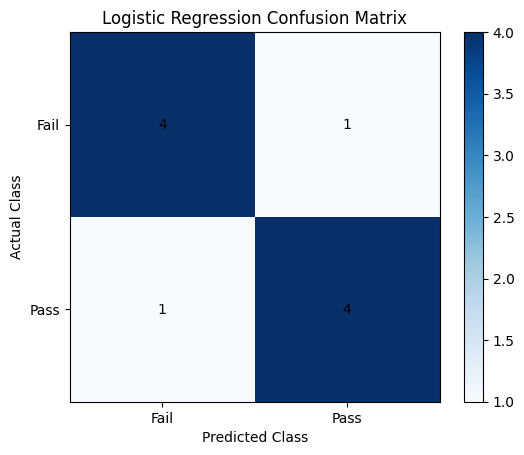


Classification Accuracy = 0.8


In [4]:

# Calculate the confusion matrix
cm = confusion_matrix(y, predictions)

print("Confusion Matrix:")
print(cm)

# Display the confusion matrix as a graph
plt.imshow(cm, cmap="Blues")

# Add labels and title
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Label the axes
plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

# Display the values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center",
                 color="black")

plt.colorbar()
plt.show()

# Display classification accuracy
print("\nClassification Accuracy =", accuracy_score(y, predictions))


### Interpretation

The logistic regression model was used to predict whether a student would pass an exam based on the number of hours studied. The model produced an intercept of -4.9828 and a regression coefficient of 0.9059.

The positive coefficient indicates that the probability of passing increases as the number of study hours increases. The sigmoid curve demonstrates this relationship, with predicted probabilities approaching 1 as study hours increase.

The confusion matrix shows that the model correctly classified 8 out of 10 students, resulting in an accuracy of 80%. Specifically, the model correctly predicted 4 failures and 4 passes, while incorrectly classifying 2 students.

These results demonstrate how logistic regression can be used to estimate probabilities and classify observations into two categories.